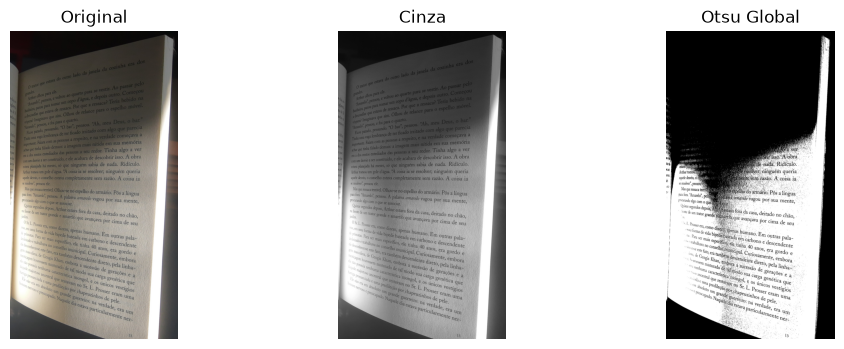

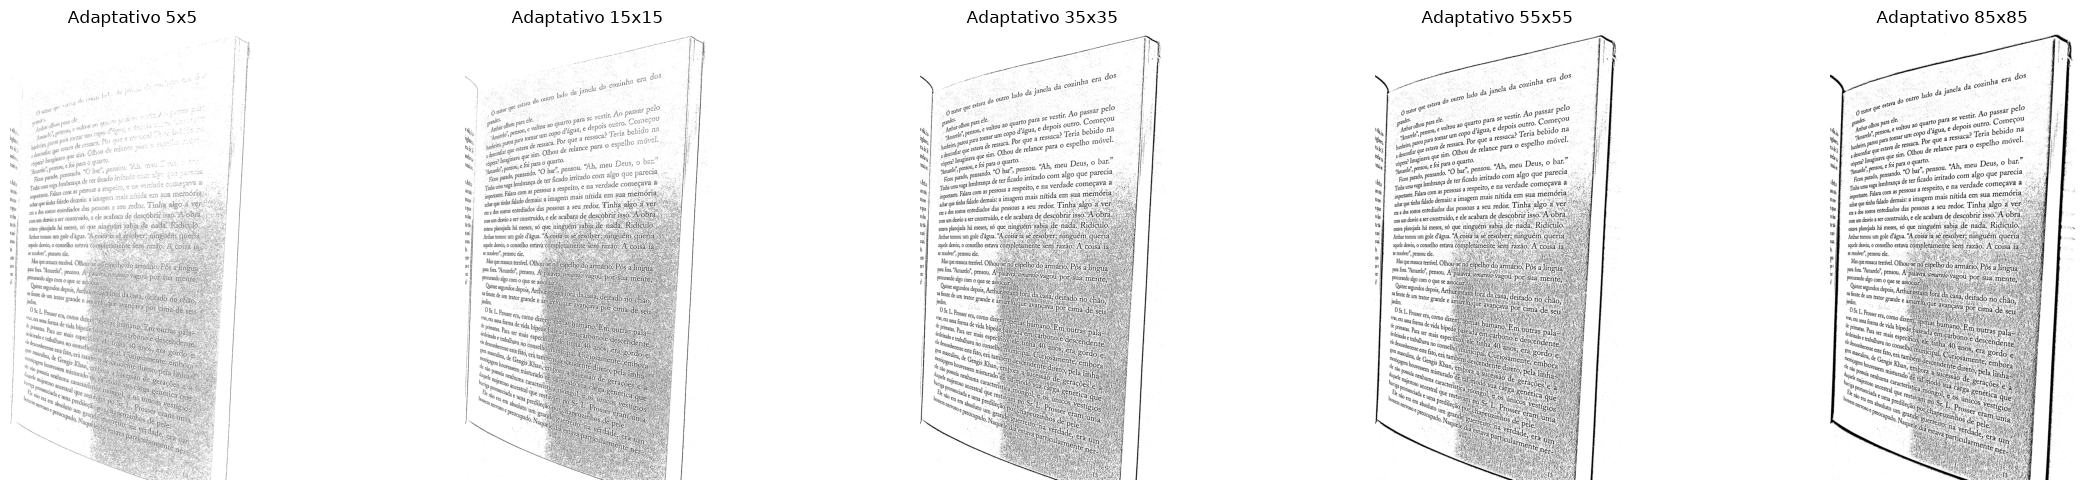

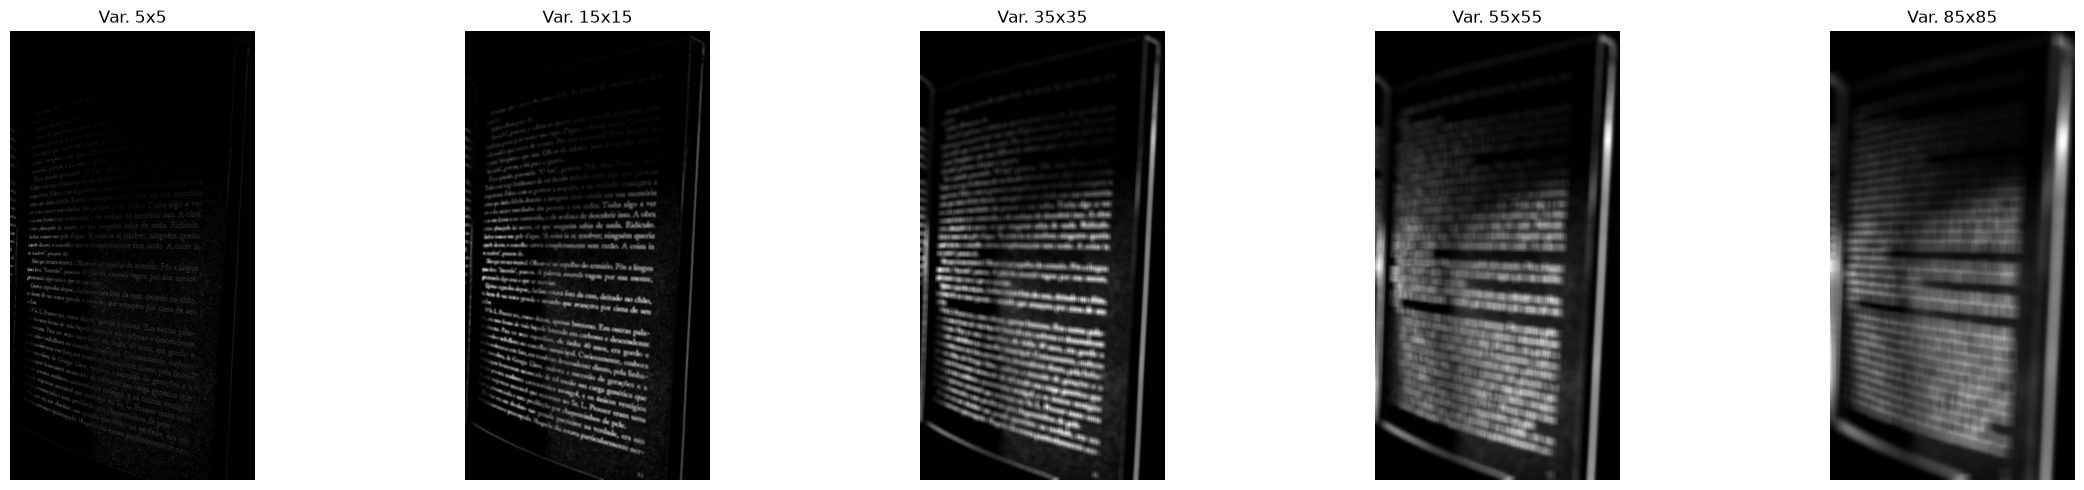

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from io import BytesIO
from urllib.request import urlopen
from PIL import Image

# Localização do arquivo de imagem
image_url = "https://raw.githubusercontent.com/florencio300/LISTA-1-PROC-SIN-II/main/dataset/guia.jpg"

# Abertura do arquivo de imagem
with urlopen(image_url) as response:
    original = Image.open(BytesIO(response.read())).convert("RGB")
    original_array = np.array(original)

# Conversão para níveis de cinza
gray = cv2.cvtColor(original_array, cv2.COLOR_RGB2GRAY)

# Limiar global por Otsu
th_otsu, otsu = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Variância local para cada janela
window_sizes = [5, 15, 35, 55, 85]
var_results = []

for ws in window_sizes:
    if ws % 2 == 0:
        ws += 1
    local_mean = cv2.blur(gray.astype(np.float32), (ws, ws))
    local_var = cv2.blur((gray.astype(np.float32) - local_mean)**2, (ws, ws))
    var_results.append((ws, local_var))

# Limiar adaptativo local
adaptive_results = []

for ws in window_sizes:
    if ws % 2 == 0:
        ws += 1
    adaptive = cv2.adaptiveThreshold(gray,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY,ws,10)
    adaptive_results.append((ws, adaptive))

# Organização dos plots em 1 linha por 8 colunas
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# Plots e títulos
# Uso de cmap = "gray" pois ao plotar, python automaticamente aplica um esquema de cores em tons de verde e azul
axes[0].imshow(original)
axes[0].set_title("Original")
axes[0].axis("off")
axes[1].imshow(gray, cmap="gray")
axes[1].set_title("Cinza")
axes[1].axis("off")
axes[2].imshow(otsu, cmap="gray")
axes[2].set_title(f"Otsu Global")
axes[2].axis("off")

fig, axes = plt.subplots(1, 5, figsize=(24, 5))

for i, (ws, img) in enumerate(adaptive_results):
    axes[i].imshow(img, cmap="gray")
    axes[i].set_title(f"Adaptativo {ws}x{ws}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

# Organização dos plots de variância em 1 linha por 5 colunas
fig, axes = plt.subplots(1, len(var_results), figsize=(24, 5))

for i, (ws, img_var) in enumerate(var_results):
    axes[i].imshow(img_var, cmap="gray")
    axes[i].set_title(f"Var. {ws}x{ws}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()